In [1]:
import torch
import torch.nn as nn
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
import umap
from sklearn.preprocessing import StandardScaler

# Device setup
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load your previous evaluation results
df = pd.read_csv("model_eval_results.csv")
print(f"Loaded {len(df)} rows from evaluation results.")
df.head()

Loaded 1184 rows from evaluation results.


,filepath,true_label,predicted_label,confidence,is_correct
0,../data/test\chihuahua\img_0_1071.jpg,chihuahua,chihuahua,0.998721,True
1,../data/test\chihuahua\img_0_1074.jpg,chihuahua,chihuahua,0.996172,True
2,../data/test\chihuahua\img_0_1082.jpg,chihuahua,chihuahua,0.996766,True
3,../data/test\chihuahua\img_0_1087.jpg,chihuahua,chihuahua,0.999047,True
4,../data/test\chihuahua\img_0_11.jpg,chihuahua,chihuahua,0.963076,True


Extracting detailed image stats...


100%|██████████| 1184/1184 [00:15<00:00, 77.75it/s]


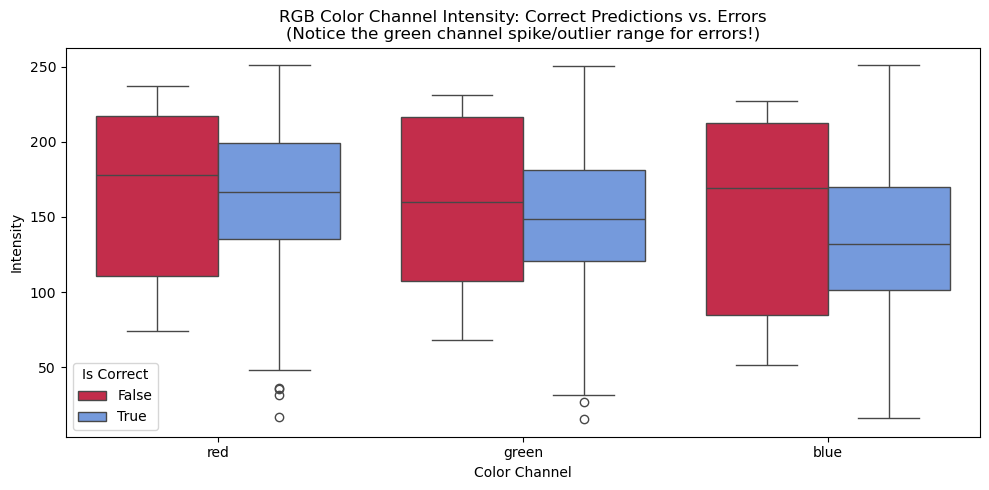

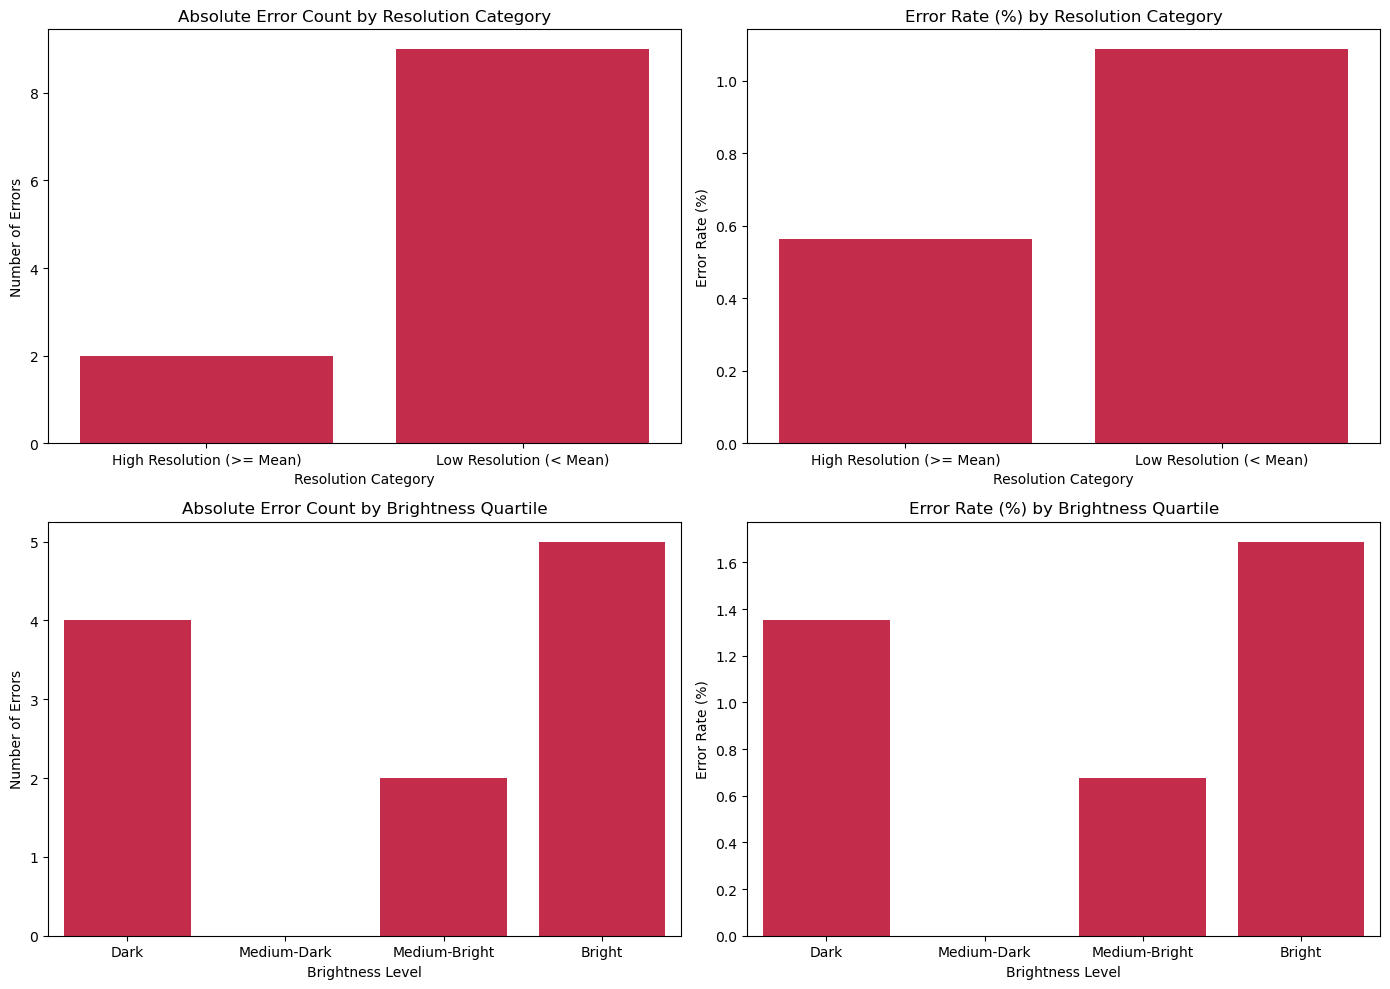

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from PIL import Image
from tqdm import tqdm

# --- 1. Enhanced Stats Extraction (RGB Channels + Resolution) ---
def extract_detailed_stats(filepath):
    try:
        img = Image.open(filepath).convert("RGB")
        width, height = img.size
        img_small = img.resize((50, 50))
        img_arr = np.array(img_small)
        
        return {
            "resolution": width * height,
            "width": width,
            "height": height,
            "brightness": np.mean(img_arr),
            "red": np.mean(img_arr[:,:,0]),
            "green": np.mean(img_arr[:,:,1]), # Crucial for catching the cannabis plant outlier!
            "blue": np.mean(img_arr[:,:,2])
        }
    except Exception as e:
        return None

print("Extracting detailed image stats...")
stats_list = [extract_detailed_stats(fp) for fp in tqdm(df["filepath"])]
stats_df = pd.DataFrame(stats_list)

# --- Merge and Create Features Safely ---
# Drop old stats columns if they exist to avoid duplicates, but keep size_category/brightness_bin safe
cols_to_drop = [c for c in ["resolution", "width", "height", "brightness", "red", "green", "blue"] if c in df.columns]
df = df.drop(columns=cols_to_drop)
df = pd.concat([df, stats_df], axis=1)

# Re-calculate categorical columns every time so re-runs never fail
mean_resolution = df["resolution"].mean()
df["size_category"] = np.where(df["resolution"] < mean_resolution, "Low Resolution (< Mean)", "High Resolution (>= Mean)")
df["brightness_bin"] = pd.qcut(df["brightness"], q=4, labels=["Dark", "Medium-Dark", "Medium-Bright", "Bright"])


# --- 2. Plot 1: 3-Channel Color Distribution (Spotting Outliers like Plants) ---
plt.figure(figsize=(10, 5))
melted_df = df.melt(id_vars=["is_correct"], value_vars=["red", "green", "blue"], 
                    var_name="Color Channel", value_name="Intensity")

sns.boxplot(x="Color Channel", y="Intensity", hue="is_correct", data=melted_df, palette={True: "cornflowerblue", False: "crimson"})
plt.title("RGB Color Channel Intensity: Correct Predictions vs. Errors\n(Notice the green channel spike/outlier range for errors!)")
plt.legend(title="Is Correct")
plt.tight_layout()
plt.show()


# --- 3. Plot 2: Error Counts & Error Rates for Resolution and Brightness ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Resolution: Absolute Error Count
sns.countplot(x="size_category", data=df[df["is_correct"] == False], color="crimson", ax=axes[0, 0])
axes[0, 0].set_title("Absolute Error Count by Resolution Category")
axes[0, 0].set_xlabel("Resolution Category")
axes[0, 0].set_ylabel("Number of Errors")

# 2. Resolution: Error Rate Percentage (%)
res_rate = df.groupby("size_category")["is_correct"].apply(lambda x: (1 - x.mean()) * 100).reset_index()
sns.barplot(x="size_category", y="is_correct", data=res_rate, color="crimson", ax=axes[0, 1])
axes[0, 1].set_title("Error Rate (%) by Resolution Category")
axes[0, 1].set_xlabel("Resolution Category")
axes[0, 1].set_ylabel("Error Rate (%)")

# 3. Brightness: Absolute Error Count
sns.countplot(x="brightness_bin", data=df[df["is_correct"] == False], color="crimson", ax=axes[1, 0])
axes[1, 0].set_title("Absolute Error Count by Brightness Quartile")
axes[1, 0].set_xlabel("Brightness Level")
axes[1, 0].set_ylabel("Number of Errors")

# 4. Brightness: Error Rate Percentage (%)
bright_rate = df.groupby("brightness_bin", observed=False)["is_correct"].apply(lambda x: (1 - x.mean()) * 100).reset_index()
sns.barplot(x="brightness_bin", y="is_correct", data=bright_rate, color="crimson", ax=axes[1, 1])
axes[1, 1].set_title("Error Rate (%) by Brightness Quartile")
axes[1, 1].set_xlabel("Brightness Level")
axes[1, 1].set_ylabel("Error Rate (%)")

plt.tight_layout()
plt.show()

In [3]:
# 1. Reduce 2048-dim features down to 2 dimensions using UMAP
print("Running UMAP projection...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42)
embedding = reducer.fit_transform(features)

# 2. Add coordinates to dataframe
df["umap_x"] = embedding[:, 0]
df["umap_y"] = embedding[:, 1]

# 3. Let's look at error rate per cluster again, but using UMAP coordinates or KMeans on the embedding
from sklearn.cluster import DBSCAN
# Optional: DBSCAN or KMeans on the 2D embedding often reveals cleaner outlier clusters of errors
kmeans_2d = KMeans(n_clusters=6, random_state=42, n_init=10)
df["cluster_2d"] = kmeans_2d.fit_predict(embedding)

print("\nAccuracy per 2D Cluster:")
print(df.groupby("cluster_2d")["is_correct"].mean())

Running UMAP projection...


NameError: name 'features' is not defined

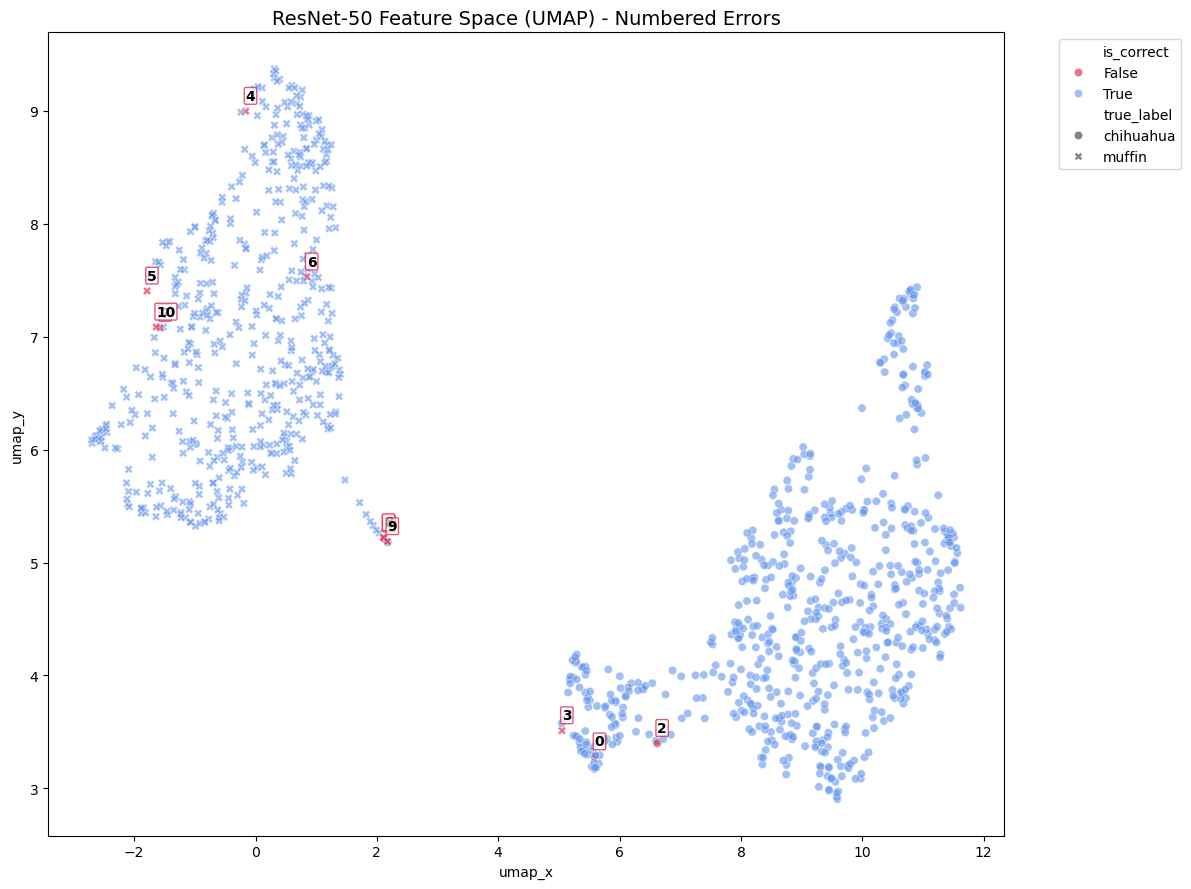


--- Inspection of all 11 Model Errors ---


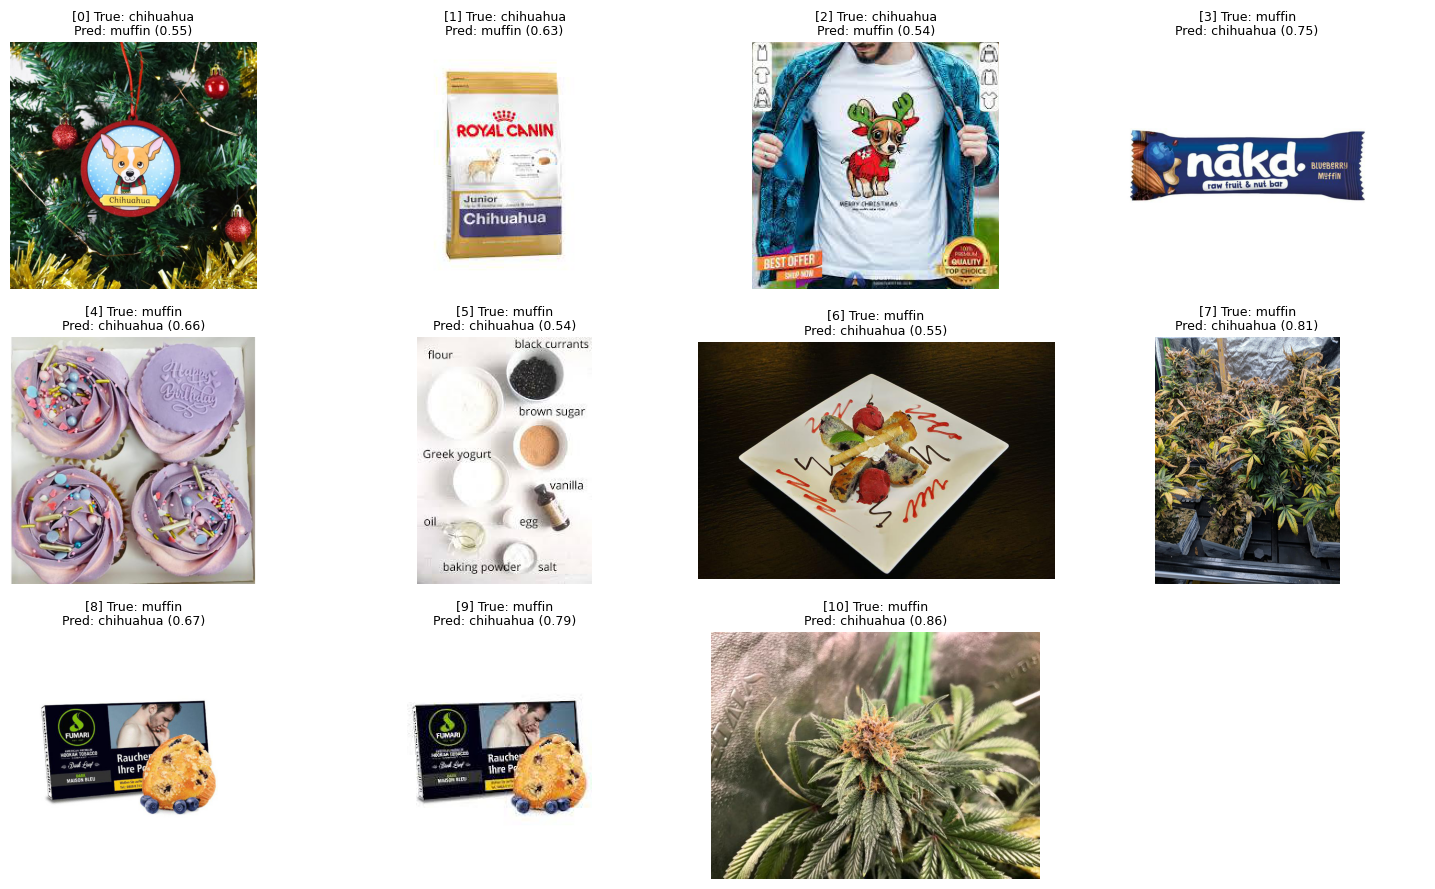

In [ ]:
# 1. Create the UMAP scatter plot
plt.figure(figsize=(12, 9))
ax = sns.scatterplot(
    x="umap_x", y="umap_y",
    hue="is_correct",
    style="true_label",
    palette={True: "cornflowerblue", False: "crimson"},
    alpha=0.6,
    data=df
)
plt.title("ResNet-50 Feature Space (UMAP) - Numbered Errors", fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# 2. Filter errors and add text numbers to the plot
errors_df = df[df["is_correct"] == False].reset_index(drop=True)

for idx, row in errors_df.iterrows():
    # Annotate the plot with the error index number
    ax.text(
        row["umap_x"], row["umap_y"] + 0.1,  # Slight Y offset so text doesn't hide the dot
        str(idx), 
        color='black', 
        weight='bold', 
        fontsize=10,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='crimson', boxstyle='round,pad=0.1')
    )

plt.tight_layout()
plt.show()

# 3. Print the corresponding images underneath in a clean grid layout
print(f"\n--- Inspection of all {len(errors_df)} Model Errors ---")
fig, axes = plt.subplots(nrows=int(np.ceil(len(errors_df) / 4)), ncols=4, figsize=(15, 3 * int(np.ceil(len(errors_df) / 4))))
axes = axes.flatten()

for idx, row in errors_df.iterrows():
    img = Image.open(row["filepath"])
    axes[idx].imshow(img)
    axes[idx].set_title(f"[{idx}] True: {row['true_label']}\nPred: {row['predicted_label']} ({row['confidence']:.2f})", fontsize=9)
    axes[idx].axis('off')

# Hide any empty subplot slots if there are leftover cells
for j in range(idx + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()